# Разведка.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
train = pd.read_csv("Data/train.csv")
test  = pd.read_csv("Data/test.csv")

print("train shape:", train.shape)
print("test  shape:", test.shape)
train.head()

train shape: (11017, 35)
test  shape: (5000, 35)


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,0.151985,2.0,1.0,0.168542,0.0,Education,0.0,23.0,5.0,2539.0,247.0,50072.0,15005.0,5569.083333,0.908289,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,0.175693,3.0,0.0,0.141553,0.0,Home,0.0,27.0,11.0,844.0,694.0,91878.0,64877.0,14345.583333,0.797339,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,0.444605,3.0,0.0,0.030987,1.0,Education,0.0,21.0,12.0,12756.0,651.0,292300.0,13918.0,25000.000000,0.915945,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,0.188452,7.0,0.0,0.379843,0.0,Debt Consolidation,0.0,27.0,21.0,1524.0,529.0,13070.0,3846.0,2890.250000,0.876416,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,0.273431,3.0,1.0,0.068659,0.0,Debt Consolidation,0.0,35.0,9.0,1973.0,128.0,33357.0,351603.0,25000.000000,0.888689,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091


In [3]:
train.info()
print("\n--- пропуски ---")
print(train.isna().sum().sort_values(ascending=False).head(20))
print("\n--- describe (числовые) ---")
display(train.describe().T)
print("\n--- describe (категориальные) ---")
display(train.describe(include="object").T)

<class 'pandas.DataFrame'>
RangeIndex: 11017 entries, 0 to 11016
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             10487 non-null  str    
 1   Age                         10487 non-null  float64
 2   AnnualIncome                10487 non-null  float64
 3   CreditScore                 9986 non-null   float64
 4   LoanAmount                  9986 non-null   float64
 5   LoanDuration                10487 non-null  float64
 6   MaritalStatus               10487 non-null  str    
 7   NumberOfDependents          10487 non-null  float64
 8   HomeOwnershipStatus         10487 non-null  str    
 9   MonthlyDebtPayments         9986 non-null   float64
 10  CreditCardUtilizationRate   10487 non-null  float64
 11  NumberOfOpenCreditLines     10487 non-null  float64
 12  NumberOfCreditInquiries     10487 non-null  float64
 13  DebtToIncomeRatio           10487 non-null

,count,mean,std,min,25%,50%,75%,max
Age,10487.0,39.850386,1.161413e+01,1.800000e+01,32.000000,40.000000,48.000000,8.000000e+01
AnnualIncome,10487.0,131587.872127,1.157919e+05,1.500000e+04,20959.500000,89015.000000,257025.000000,7.485080e+05
CreditScore,9986.0,678.082716,1.751925e+02,3.000000e+02,550.000000,722.500000,850.000000,8.500000e+02
LoanAmount,9986.0,29874.218306,2.770551e+04,1.063000e+03,12658.000000,21828.500000,37158.000000,4.189970e+05
LoanDuration,10487.0,53.439878,2.449356e+01,1.200000e+01,36.000000,48.000000,60.000000,1.200000e+02
NumberOfDependents,10487.0,1.568323,1.418684e+00,0.000000e+00,0.000000,1.000000,3.000000,6.000000e+00
MonthlyDebtPayments,9986.0,546.458642,5.019819e+02,1.300000e+01,233.250000,398.000000,685.000000,1.087900e+04
CreditCardUtilizationRate,10487.0,0.284397,1.592405e-01,3.673558e-03,0.158929,0.262229,0.391683,9.146347e-01
NumberOfOpenCreditLines,10487.0,3.033565,1.740186e+00,0.000000e+00,2.000000,3.000000,4.000000,1.200000e+01
NumberOfCreditInquiries,10487.0,0.979498,9.909274e-01,0.000000e+00,0.000000,1.000000,2.000000,6.000000e+00



--- describe (категориальные) ---


C:\Users\Kostya\AppData\Local\Temp\ipykernel_33856\2349274714.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(train.describe(include="object").T)


,count,unique,top,freq
ApplicationDate,10487,10000,1988-12-02,3
MaritalStatus,10487,4,Married,5145
HomeOwnershipStatus,10487,4,Mortgage,4148
LoanPurpose,9986,5,Home,2981
EmploymentStatus,10487,3,Employed,9059
EducationLevel,10487,5,High School,4234


In [4]:
num_cols = train.select_dtypes(include=np.number).columns.tolist()
cat_cols = train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
target   = "RiskScore"

print("Числовые признаки:", len(num_cols))
print(num_cols)
print("\nКатегориальные:", len(cat_cols))
print(cat_cols)

Числовые признаки: 29
['Age', 'AnnualIncome', 'CreditScore', 'LoanAmount', 'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHistory', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory', 'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets', 'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory', 'JobTenure', 'Experience', 'NetWorth', 'BaseInterestRate', 'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'RiskScore']

Категориальные: 6
['ApplicationDate', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']


C:\Users\Kostya\AppData\Local\Temp\ipykernel_33856\834616580.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [5]:
print("Полные дубликаты строк:", train.duplicated().sum())

for col in train.columns:
    nun = train[col].nunique(dropna=False)
    if nun <= 1:
        print(f"!! {col}: {nun} уникальных значений — константа")
    elif nun <= 5:
        print(f"   {col}: {nun} уникальных значений")

Полные дубликаты строк: 1016
   MaritalStatus: 5 уникальных значений
   HomeOwnershipStatus: 5 уникальных значений
   BankruptcyHistory: 3 уникальных значений
   PreviousLoanDefaults: 3 уникальных значений
   EmploymentStatus: 4 уникальных значений


# Графики, графики, графики.

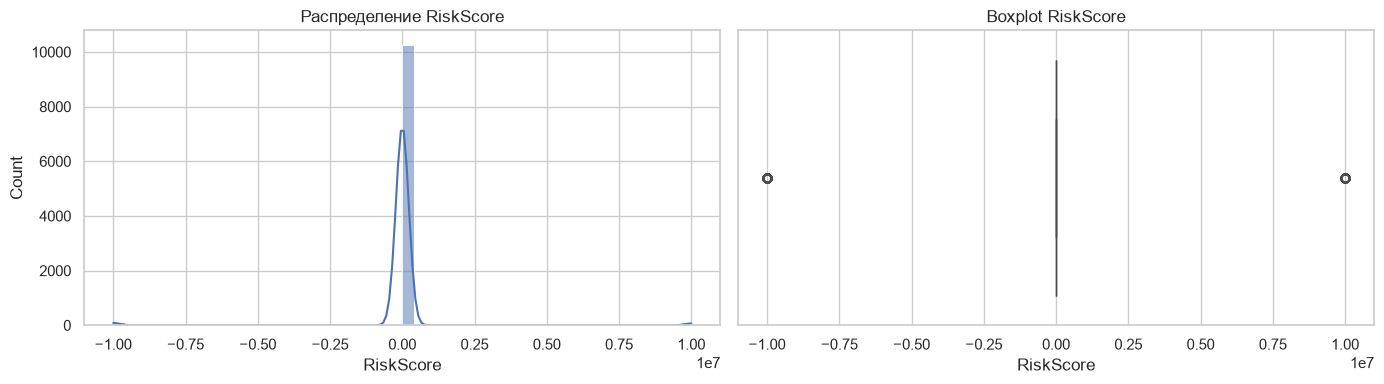

count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64
Асимметрия (skew): -0.8237467971274451
Эксцесс (kurt): 45.769502407560964


In [6]:
#Целевая переменная симметрично распределена колоколом выбросов и вбросов нет
# BoxPlot 0-ой
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train[target], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Распределение RiskScore")

sns.boxplot(x=train[target], ax=axes[1])
axes[1].set_title("Boxplot RiskScore")

plt.tight_layout()
plt.show()

print(train[target].describe())
print("Асимметрия (skew):", train[target].skew())
print("Эксцесс (kurt):", train[target].kurt())

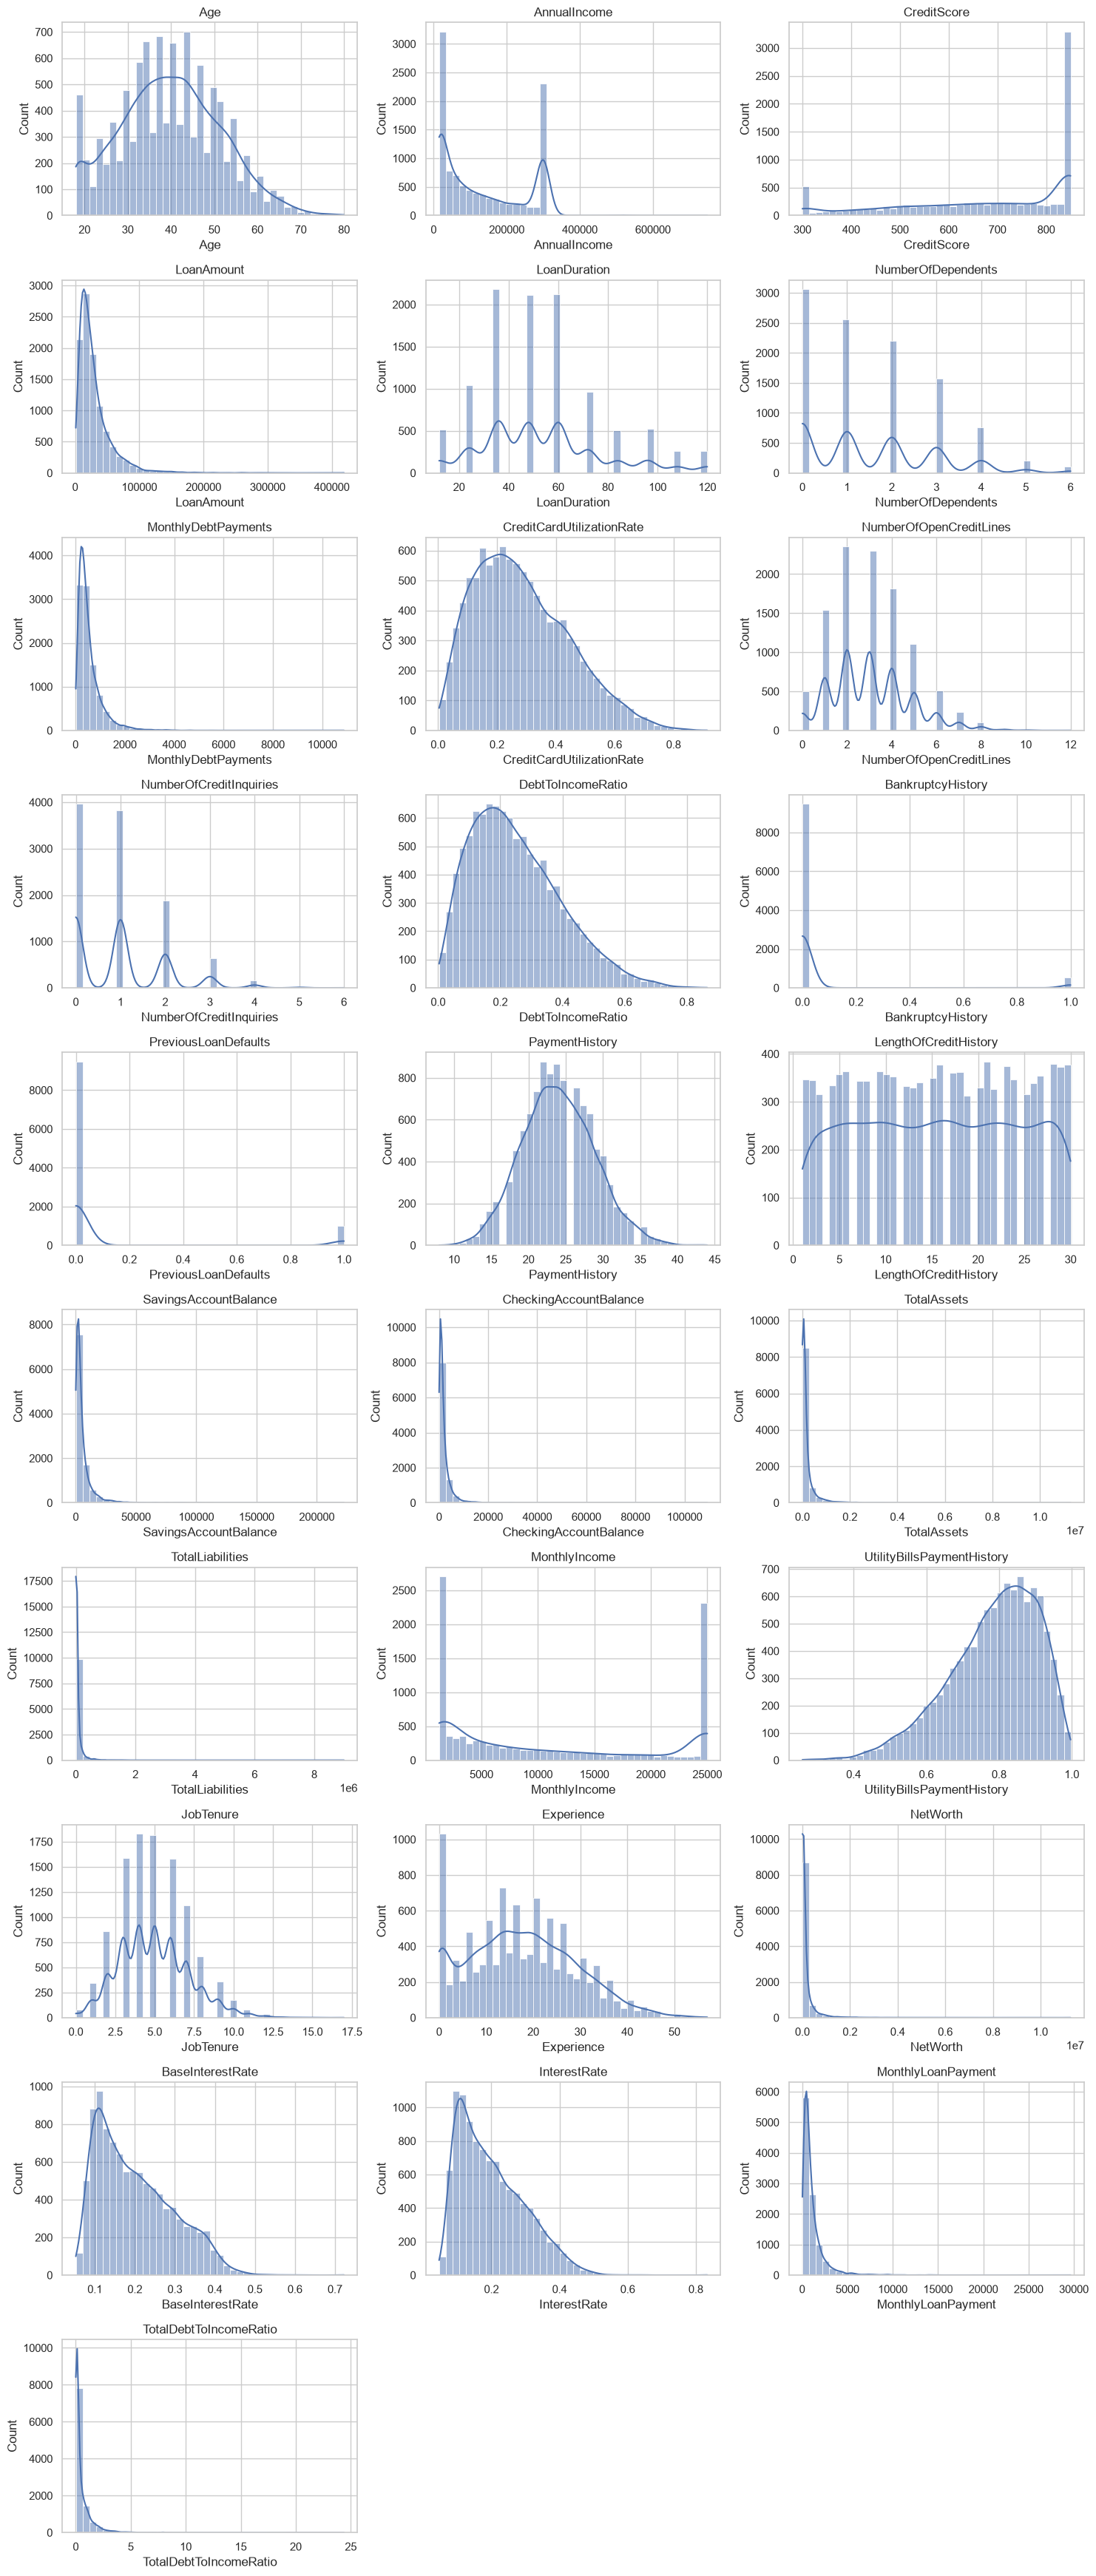

In [7]:
plot_cols = [c for c in num_cols if c != target]

n = len(plot_cols)
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(15, 3.5 * ((n + 2) // 3)))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    sns.histplot(train[col], bins=40, kde=True, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [8]:
corr_with_target = (
    train[num_cols]
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
print(corr_with_target.head(15))

NumberOfDependents           -0.023314
PaymentHistory                0.019144
TotalDebtToIncomeRatio        0.013879
UtilityBillsPaymentHistory   -0.013865
MonthlyLoanPayment            0.012366
LoanAmount                    0.011771
NumberOfCreditInquiries       0.011055
LengthOfCreditHistory        -0.009448
NetWorth                      0.008804
AnnualIncome                 -0.008460
TotalAssets                   0.008092
SavingsAccountBalance         0.007611
DebtToIncomeRatio            -0.007417
MonthlyIncome                -0.006145
CreditCardUtilizationRate     0.005501
Name: RiskScore, dtype: float64


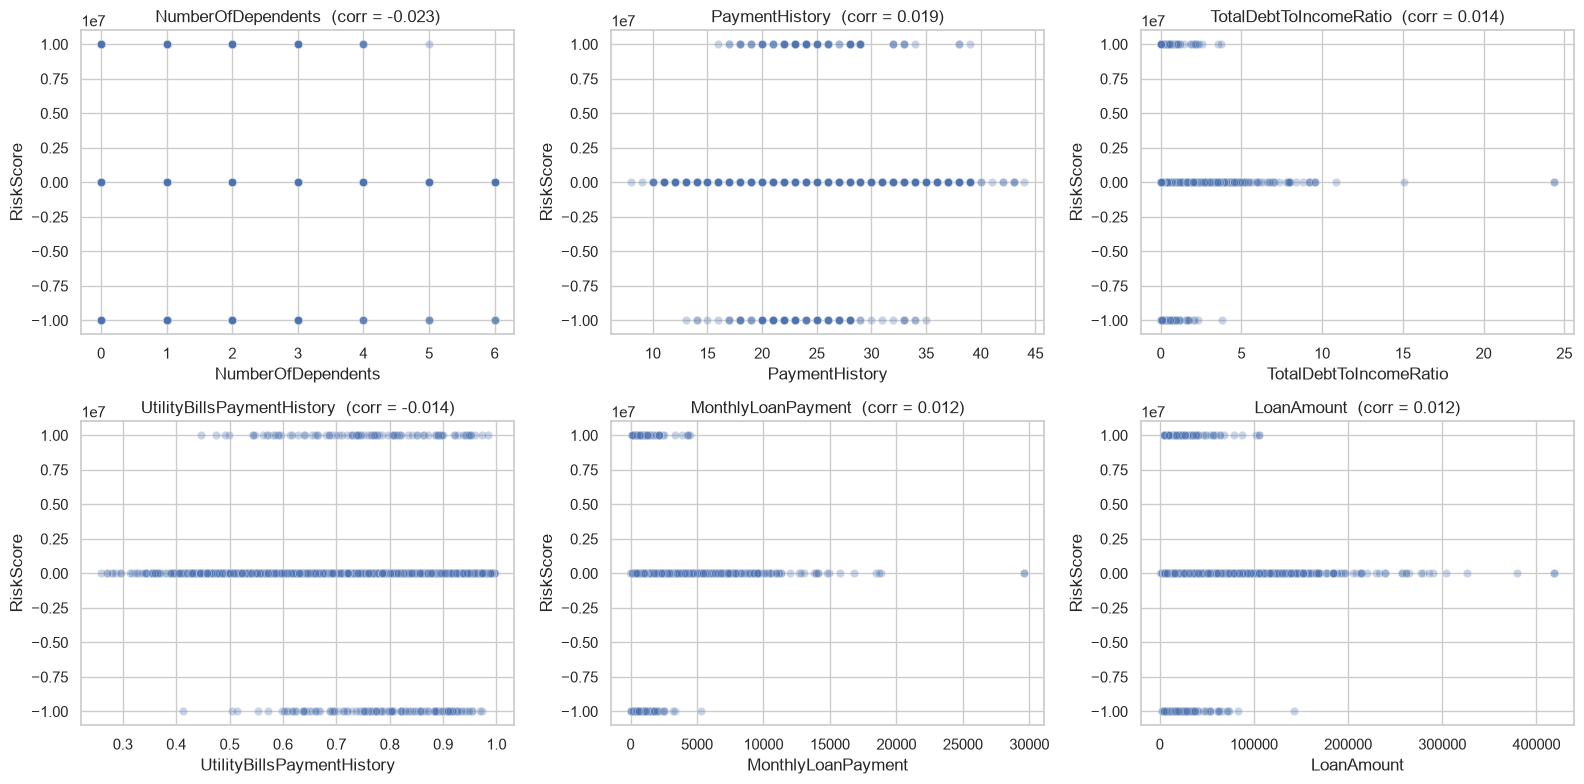

In [9]:
top_cols = corr_with_target.head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(top_cols):
    sns.scatterplot(data=train, x=col, y=target, alpha=0.3, ax=axes[i])
    axes[i].set_title(f"{col}  (corr = {corr_with_target[col]:.3f})")
plt.tight_layout()
plt.show()

Берём в графики: ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']
Пропускаем (слишком много категорий): ['ApplicationDate']


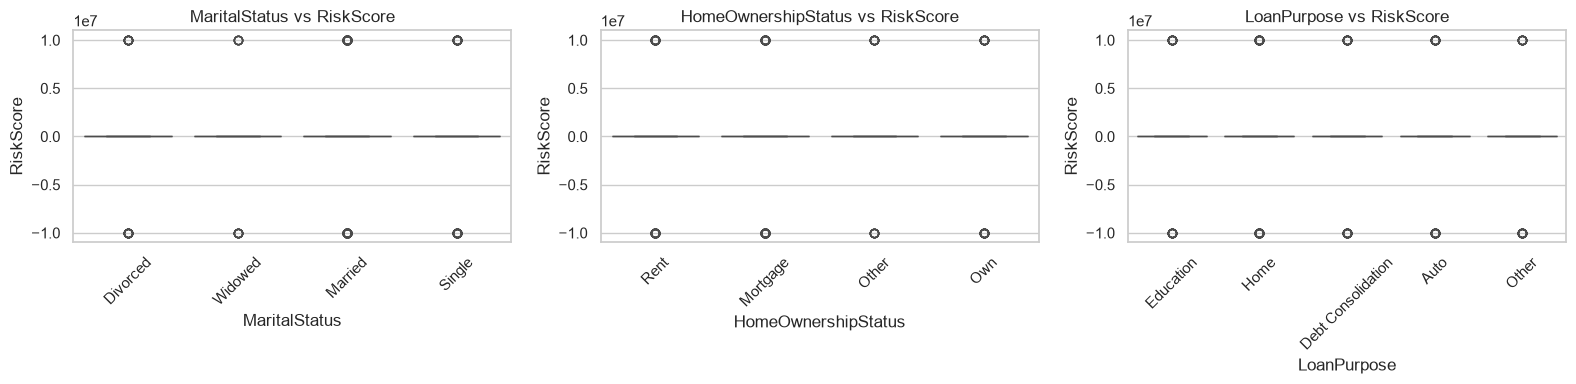

In [10]:
low_card = [c for c in cat_cols if train[c].nunique() <= 20]

print("Берём в графики:", low_card)
print("Пропускаем (слишком много категорий):", [c for c in cat_cols if c not in low_card])

if low_card:
    show_cols = low_card[:3]
    fig, axes = plt.subplots(1, len(show_cols), figsize=(16, 4))
    axes = np.atleast_1d(axes)
    for i, col in enumerate(show_cols):
        sns.boxplot(data=train, x=col, y=target, ax=axes[i])
        axes[i].tick_params(axis="x", rotation=45)
        axes[i].set_title(f"{col} vs {target}")
    plt.tight_layout()
    plt.show()
else:
    print("Нет категориальных признаков с малым числом уровней — пропускаем шаг")

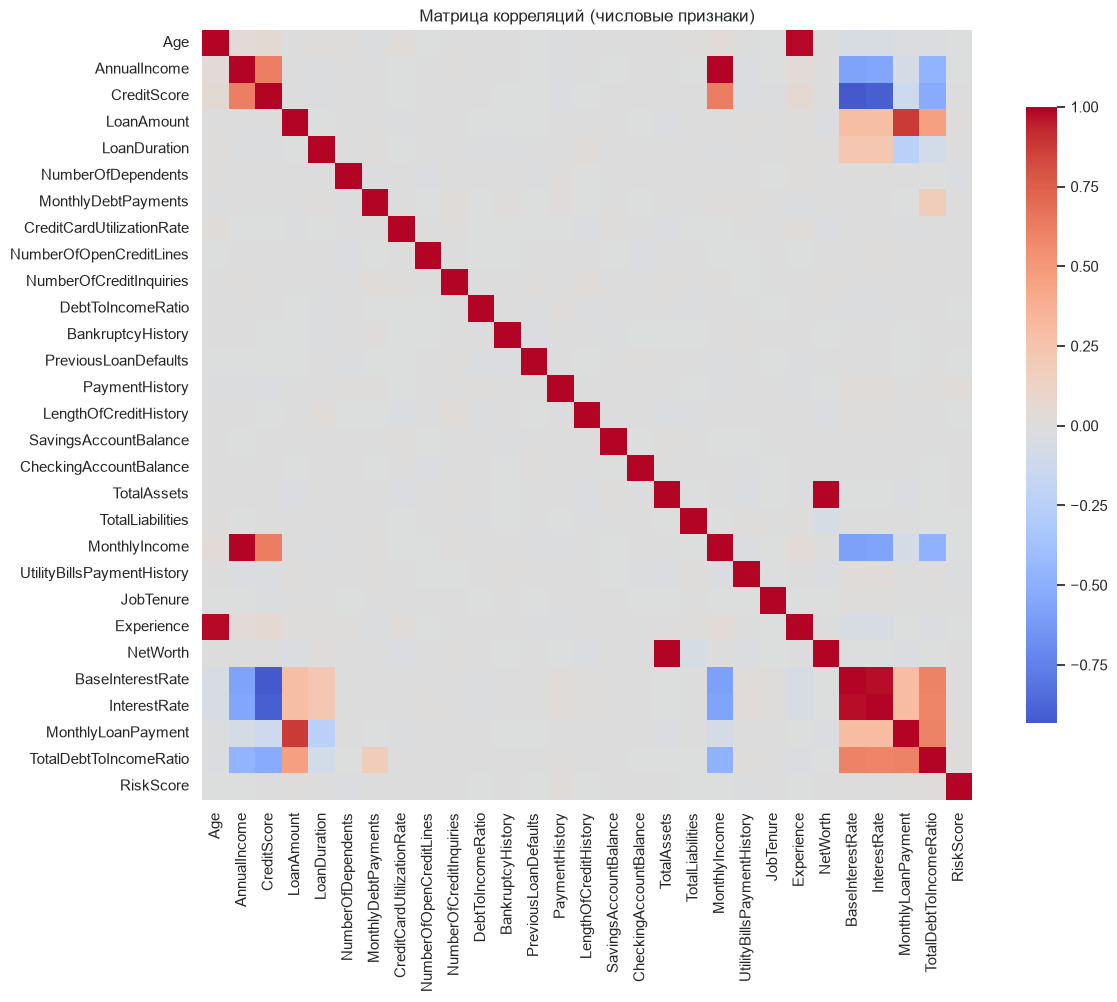

In [11]:
corr = train[num_cols].corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0,
            annot=False, square=True, cbar_kws={"shrink": 0.8})
plt.title("Матрица корреляций (числовые признаки)")
plt.show()

In [12]:
print("Корреляция с RiskScore:")
print(corr[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False).head(15))

corr_abs = corr.abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
high_pairs = upper.stack().sort_values(ascending=False).head(10)
print("\nТоп взаимных корреляций признак–признак:")
print(high_pairs)

Корреляция с RiskScore:
NumberOfDependents           -0.023314
PaymentHistory                0.019144
TotalDebtToIncomeRatio        0.013879
UtilityBillsPaymentHistory   -0.013865
MonthlyLoanPayment            0.012366
LoanAmount                    0.011771
NumberOfCreditInquiries       0.011055
LengthOfCreditHistory        -0.009448
NetWorth                      0.008804
AnnualIncome                 -0.008460
TotalAssets                   0.008092
SavingsAccountBalance         0.007611
DebtToIncomeRatio            -0.007417
MonthlyIncome                -0.006145
CreditCardUtilizationRate     0.005501
Name: RiskScore, dtype: float64

Топ взаимных корреляций признак–признак:
TotalAssets       NetWorth                  0.994042
AnnualIncome      MonthlyIncome             0.985384
Age               Experience                0.982995
BaseInterestRate  InterestRate              0.975359
CreditScore       BaseInterestRate          0.931766
                  InterestRate              0.907621

# Теперь от разведки к действиям.

|y| >        100:   215 строк (  1.95%)
|y| >        200:   215 строк (  1.95%)
|y| >        500:   215 строк (  1.95%)
|y| >      1,000:   215 строк (  1.95%)
|y| >     10,000:   215 строк (  1.95%)
|y| >  1,000,000:   215 строк (  1.95%)

Описательные для |y| <= 200:
count    10272.00
mean        48.36
std         17.24
min         14.84
25%         32.72
50%         44.20
75%         65.12
max         97.60
Name: RiskScore, dtype: float64


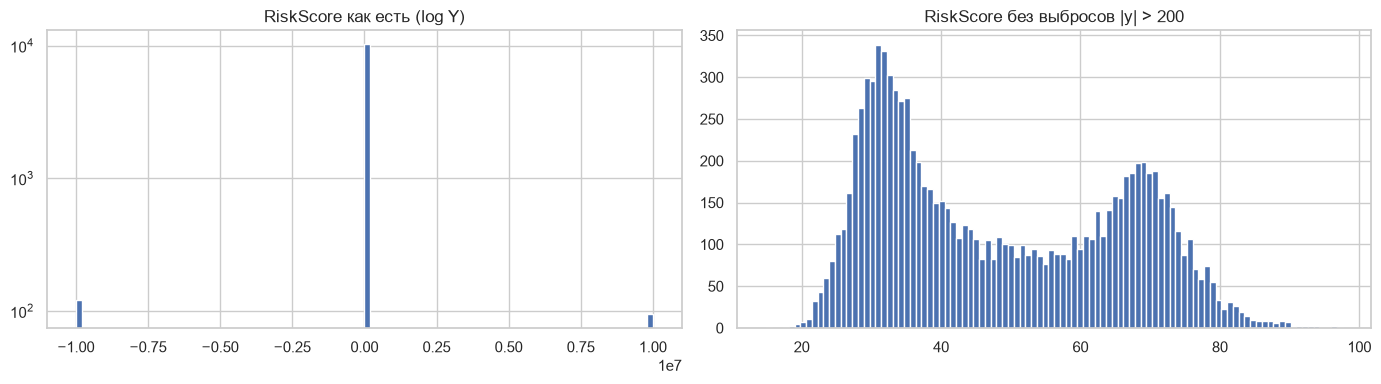

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y = train["RiskScore"]

for thr in [100, 200, 500, 1_000, 10_000, 1_000_000]:
    n = (y.abs() > thr).sum()
    print(f"|y| > {thr:>10,}: {n:>5} строк ({n / len(y) * 100:6.2f}%)")

print("\nОписательные для |y| <= 200:")
print(y[y.abs() <= 200].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(y, bins=100)
axes[0].set_yscale("log")
axes[0].set_title("RiskScore как есть (log Y)")
axes[1].hist(y[y.abs() <= 200], bins=100)
axes[1].set_title("RiskScore без выбросов |y| > 200")
plt.tight_layout()
plt.show()

RiskScore
-9999999.0     121
 10000000.0     94
Name: count, dtype: int64
CreditScore              -0.785
MonthlyIncome            -0.770
BaseInterestRate          0.759
AnnualIncome             -0.759
InterestRate              0.743
TotalDebtToIncomeRatio    0.531
BankruptcyHistory         0.178
MonthlyLoanPayment        0.151
TotalAssets              -0.146
NetWorth                 -0.145
Name: RiskScore, dtype: float64


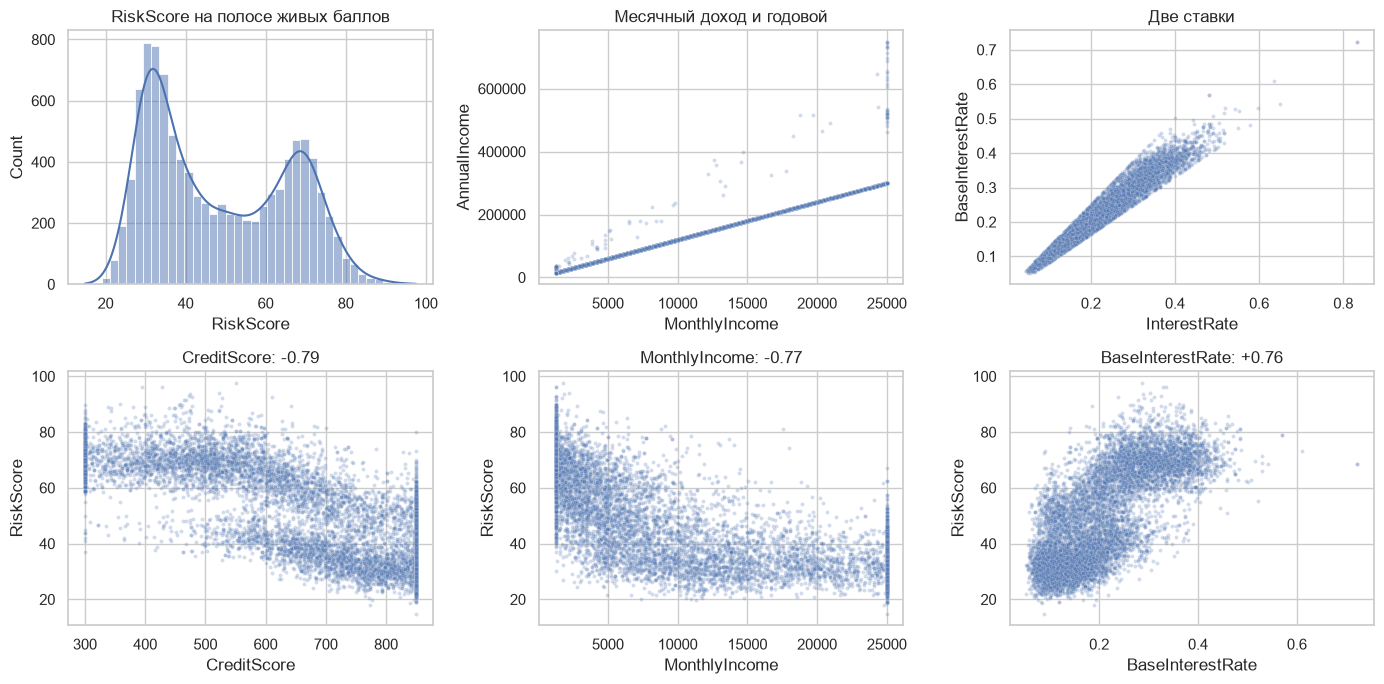

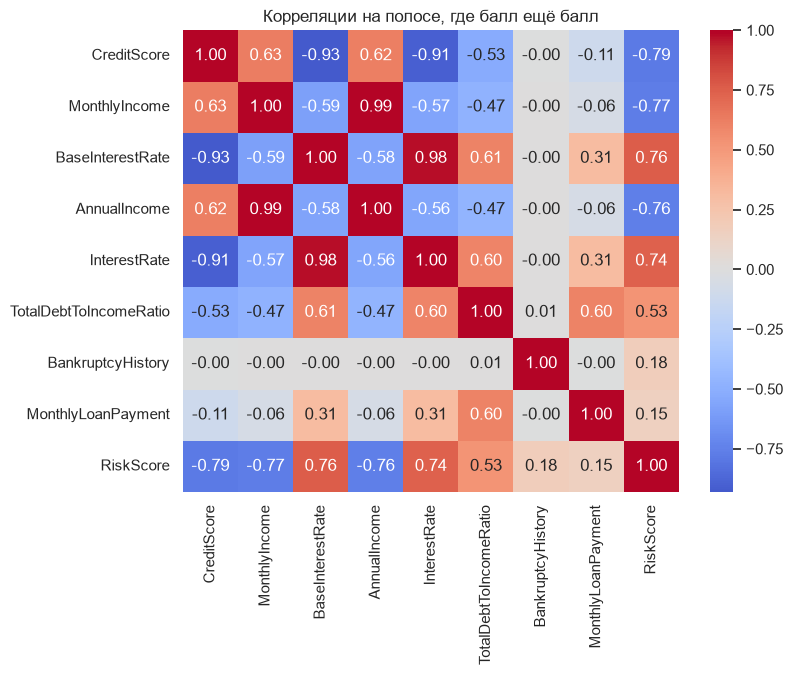

In [14]:
band = train.dropna(subset=["RiskScore"]).copy()
print(band.loc[~band["RiskScore"].between(0, 100), "RiskScore"].value_counts())
band = band.loc[band["RiskScore"].between(0, 100)].copy()
y = band["RiskScore"].to_numpy()
num = band.select_dtypes(include=np.number).columns.drop("RiskScore")
corr_y = band[num.tolist() + ["RiskScore"]].corr()["RiskScore"].drop("RiskScore").sort_values(key=np.abs, ascending=False)
print(corr_y.head(10).round(3))
top = corr_y.head(4).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
sns.histplot(band["RiskScore"], bins=40, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("RiskScore на полосе живых баллов")
sns.scatterplot(data=band, x="MonthlyIncome", y="AnnualIncome", s=8, alpha=0.25, ax=axes[0, 1])
axes[0, 1].set_title("Месячный доход и годовой")
sns.scatterplot(data=band, x="InterestRate", y="BaseInterestRate", s=8, alpha=0.25, ax=axes[0, 2])
axes[0, 2].set_title("Две ставки")
for ax, col in zip(axes[1], top[:3]):
    sns.scatterplot(data=band, x=col, y="RiskScore", s=8, alpha=0.25, ax=ax)
    ax.set_title(f"{col}: {corr_y[col]:+.2f}")
plt.tight_layout()
plt.show()
keep = corr_y.head(8).index.tolist() + ["RiskScore"]
plt.figure(figsize=(8, 6))
sns.heatmap(band[keep].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Корреляции на полосе, где балл ещё балл")
plt.show()


In [15]:
class ZScore:
    def fit(self, X):
        X = np.asarray(X, float)
        self.mu_ = X.mean(axis=0)
        self.sd_ = X.std(axis=0)
        self.sd_[self.sd_ < 1e-12] = 1.0
        return self
    def transform(self, X):
        return (np.asarray(X, float) - self.mu_) / self.sd_
    def fit_transform(self, X):
        return self.fit(X).transform(X)

class MinMax:
    def fit(self, X):
        X = np.asarray(X, float)
        self.lo_ = X.min(axis=0)
        span = X.max(axis=0) - self.lo_
        span[span < 1e-12] = 1.0
        self.span_ = span
        return self
    def transform(self, X):
        return (np.asarray(X, float) - self.lo_) / self.span_
    def fit_transform(self, X):
        return self.fit(X).transform(X)

col = band["CreditScore"].dropna().to_numpy(dtype=float).reshape(-1, 1)
zs = ZScore().fit_transform(col)
mm = MinMax().fit_transform(col)
print("z-score vs formula", np.max(np.abs(zs - (col - col.mean()) / col.std())))
print("min-max vs formula", np.max(np.abs(mm - (col - col.min()) / (col.max() - col.min()))))
from sklearn.preprocessing import MinMaxScaler, StandardScaler
print("z-score vs sklearn", np.max(np.abs(zs - StandardScaler().fit_transform(col))))
print("min-max vs sklearn", np.max(np.abs(mm - MinMaxScaler().fit_transform(col))))


z-score vs formula 0.0
min-max vs formula 0.0
z-score vs sklearn 0.0
min-max vs sklearn 1.1102230246251565e-16


In [16]:
class MyLinearRegression:
    def __init__(self, method="analytic", lr=0.1, n_iter=800, batch_size=128, l1=0.0, l2=0.0, p=2.0, lp=0.0, fit_intercept=True, rs=42):
        self.method = method
        self.lr = lr
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.l1 = l1
        self.l2 = l2
        self.p = p
        self.lp = lp
        self.fit_intercept = fit_intercept
        self.rs = rs

    def _design(self, X):
        X = np.asarray(X, float)
        if self.fit_intercept:
            return np.column_stack([np.ones(len(X)), X])
        return X

    def fit(self, X, y):
        X = self._design(X)
        y = np.asarray(y, float).ravel()
        n, d = X.shape
        pen = np.ones(d)
        if self.fit_intercept:
            pen[0] = 0.0
        if self.method == "analytic" and self.l1 == 0.0 and self.lp == 0.0:
            if self.l2 == 0.0:
                self.w_ = np.linalg.lstsq(X, y, rcond=None)[0]
            else:
                xa = np.vstack([X, np.sqrt(self.l2) * np.diag(pen)])
                ya = np.concatenate([y, np.zeros(d)])
                self.w_ = np.linalg.lstsq(xa, ya, rcond=None)[0]
            return self
        rng = np.random.default_rng(self.rs)
        w = np.zeros(d)
        for t in range(self.n_iter):
            if self.method == "sgd":
                bi = rng.choice(n, size=min(self.batch_size, n), replace=False)
                step = self.lr / np.sqrt(t + 1.0)
            else:
                bi = slice(None)
                step = self.lr
            xb, yb = X[bi], y[bi]
            m = len(yb)
            grad = (xb.T @ (xb @ w - yb)) / m
            coef = pen > 0
            if self.l2:
                scale = (1.0 / m) if (self.l1 == 0.0 and self.lp == 0.0) else 1.0
                grad[coef] += scale * self.l2 * w[coef]
            if self.lp:
                ww = w[coef]
                grad[coef] += self.lp * (np.abs(ww) + 1e-8) ** (self.p - 1.0) * np.sign(ww)
            w = w - step * grad
            if self.l1:
                z = w[coef]
                w[coef] = np.sign(z) * np.maximum(np.abs(z) - step * self.l1, 0.0)
        self.w_ = w
        return self

    def predict(self, X):
        return self._design(X) @ self.w_

def mse(y, p):
    e = np.asarray(y) - np.asarray(p)
    return float(np.mean(e * e))

def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))

def r2(y, p):
    y = np.asarray(y, float)
    p = np.asarray(p, float)
    return float(1.0 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))

def mape(y, p):
    y = np.asarray(y, float)
    return float(np.mean(np.abs((y - p) / np.maximum(np.abs(y), 1e-8))))

def one_hot(df, levels):
    cols = []
    for c, cats in levels.items():
        s = df[c].astype(str)
        for level in cats[1:]:
            cols.append((s == level).to_numpy(dtype=float))
    return np.column_stack(cols)

def kfold_mse(factory, X, y, k=5, seed=42):
    idx = np.arange(len(X))
    rng = np.random.default_rng(seed)
    rng.shuffle(idx)
    parts = np.array_split(idx, k)
    out = []
    for i in range(k):
        te = parts[i]
        tr = np.concatenate([parts[j] for j in range(k) if j != i])
        model = factory()
        model.fit(X[tr], y[tr])
        out.append(mse(y[te], model.predict(X[te])))
    return np.asarray(out, float)


In [17]:
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression as SkLR, Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

CATS = ["MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "EmploymentStatus", "EducationLevel"]
num_cols = [c for c in band.columns if c not in CATS and c not in ("RiskScore", "ApplicationDate")]
filled = band[num_cols].apply(pd.to_numeric, errors="coerce")
filled = filled.fillna(filled.median())
levels = {c: sorted(band[c].dropna().astype(str).unique()) for c in CATS}
plain = np.hstack([filled.to_numpy(dtype=float), one_hot(band, levels)])
rng = np.random.default_rng(0)
take = rng.choice(len(plain), size=2500, replace=False)
P, yp = plain[take], y[take]
cut = int(0.8 * len(P))
demo = ZScore().fit(P[:cut])
A, B = demo.transform(P[:cut]), demo.transform(P[cut:])
ya, yb = yp[:cut], yp[cut:]
ours = MyLinearRegression(method="analytic").fit(A, ya)
sk = SkLR().fit(A, ya)
pred, sk_pred = ours.predict(B), sk.predict(B)
print("analytic MSE", mse(yb, pred), "sklearn", mean_squared_error(yb, sk_pred))
print("max |coef|", np.max(np.abs(ours.w_[1:] - sk.coef_)), "intercept", abs(ours.w_[0] - sk.intercept_))
gd = MyLinearRegression(method="gd", lr=0.2, n_iter=1500).fit(A, ya)
sgd = MyLinearRegression(method="sgd", lr=0.15, n_iter=2500, batch_size=128).fit(A, ya)
print("gd MSE", mse(yb, gd.predict(B)), "sgd MSE", mse(yb, sgd.predict(B)))
print("MAE", mae(yb, pred), mean_absolute_error(yb, pred))
print("R2", r2(yb, pred), r2_score(yb, pred))
print("MAPE", mape(yb, pred), mean_absolute_percentage_error(yb, pred))


analytic MSE 56.72698955417378 sklearn 56.726989554173784
max |coef| 1.0391687510491465e-13 intercept 7.105427357601002e-15
gd MSE 56.799853101321 sgd MSE 57.52533706397277
MAE 6.1421356445815505 6.1421356445815505
R2 0.8188988381474537 0.8188988381474537
MAPE 0.1365891881668391 0.1365891881668391


In [18]:
ridge = MyLinearRegression(method="analytic", l2=10.0).fit(A, ya)
sk_r = Ridge(alpha=10.0).fit(A, ya)
print("L2 analytic", mse(yb, ridge.predict(B)), "Ridge", mse(yb, sk_r.predict(B)), "max |coef|", np.max(np.abs(ridge.w_[1:] - sk_r.coef_)))
gd_ridge = MyLinearRegression(method="gd", lr=0.2, n_iter=2500, l2=10.0).fit(A, ya)
print("L2 gradient", mse(yb, gd_ridge.predict(B)))
las = MyLinearRegression(method="gd", lr=0.2, n_iter=2500, l1=0.05).fit(A, ya)
sk_l = Lasso(alpha=0.05, max_iter=20000).fit(A, ya)
print("L1", mse(yb, las.predict(B)), "Lasso", mse(yb, sk_l.predict(B)), "zeros", int(np.sum(np.abs(las.w_[1:]) < 1e-6)), int(np.sum(np.abs(sk_l.coef_) < 1e-6)))
en = MyLinearRegression(method="gd", lr=0.2, n_iter=2500, l1=0.02, l2=0.02).fit(A, ya)
sk_e = ElasticNet(alpha=0.04, l1_ratio=0.5, max_iter=20000).fit(A, ya)
print("L1+L2", mse(yb, en.predict(B)), "ElasticNet", mse(yb, sk_e.predict(B)))
lp = MyLinearRegression(method="gd", lr=0.15, n_iter=2000, lp=0.05, p=1.5).fit(A, ya)
print("Lp p=1.5", mse(yb, lp.predict(B)))
lp2 = MyLinearRegression(method="gd", lr=0.2, n_iter=2500, lp=10.0 / len(ya), p=2.0).fit(A, ya)
print("Lp p=2", mse(yb, lp2.predict(B)), "same L2 as above", mse(yb, sk_r.predict(B)))


L2 analytic 57.0242020862785 Ridge 57.02420208627846 max |coef| 1.091793322416379e-12
L2 gradient 57.0265278388129
L1 56.85843741572173 Lasso 56.86046570248044 zeros 11 11
L1+L2 57.45869152358052 ElasticNet 57.45737089941984
Lp p=1.5 57.391617588349824
Lp p=2 57.02652783928473 same L2 as above 57.02420208627846


In [19]:
class FoldModel:
    def __init__(self, impl="ours", l2=0.0):
        self.impl = impl
        self.l2 = l2
    def fit(self, X, y):
        self.sc_ = ZScore().fit(np.asarray(X, float))
        Z = self.sc_.transform(X)
        if self.impl == "ours":
            self.m_ = MyLinearRegression(method="analytic", l2=self.l2).fit(Z, y)
        elif self.l2:
            self.m_ = Ridge(alpha=self.l2).fit(Z, y)
        else:
            self.m_ = SkLR().fit(Z, y)
        return self
    def predict(self, X):
        return self.m_.predict(self.sc_.transform(X))

loo_rows = 200
loo_x, loo_y = plain[:loo_rows], y[:loo_rows]
loo_ours = kfold_mse(lambda: FoldModel("ours", 0.0), loo_x, loo_y, k=loo_rows, seed=0)
loo_sk = kfold_mse(lambda: FoldModel("sklearn", 0.0), loo_x, loo_y, k=loo_rows, seed=0)
print("LOO", loo_ours.mean(), "sklearn", loo_sk.mean())


LOO 58.877720471360135 sklearn 58.87772047136008


In [20]:
KEY = ["CreditScore", "InterestRate", "BaseInterestRate", "MonthlyIncome", "AnnualIncome",
       "TotalDebtToIncomeRatio", "DebtToIncomeRatio", "LoanAmount", "MonthlyLoanPayment",
       "TotalAssets", "NetWorth", "BankruptcyHistory", "CreditCardUtilizationRate"]
PAIRS = [("CreditScore", "InterestRate"), ("CreditScore", "TotalDebtToIncomeRatio"),
         ("CreditScore", "MonthlyIncome"), ("InterestRate", "TotalDebtToIncomeRatio"),
         ("InterestRate", "MonthlyIncome"), ("MonthlyIncome", "LoanAmount"),
         ("AnnualIncome", "LoanAmount"), ("MonthlyLoanPayment", "MonthlyIncome"),
         ("NetWorth", "InterestRate"), ("TotalAssets", "InterestRate"),
         ("CreditScore", "BankruptcyHistory")]

def numeric_block(df, cols, bounds, med, knots):
    out, raw = [], {}
    for c in cols:
        x = pd.to_numeric(df[c], errors="coerce").to_numpy(dtype=float)
        lo, hi = bounds[c]
        x = np.clip(x, lo, hi)
        x = np.where(np.isnan(x), med[c], x)
        raw[c] = x
        out.extend([x, np.log1p(np.abs(x)), x ** 2, 1.0 / (np.abs(x) + 1.0)])
    for c in KEY:
        x = raw[c]
        out.append(x ** 3)
        out.append(np.sqrt(np.abs(x)))
        for knot in knots[c]:
            out.append(np.maximum(0.0, x - knot))
    for a, b in PAIRS:
        out.append(raw[a] * raw[b])
        out.append(np.log1p(np.abs(raw[a])) * raw[b])
    out.append(raw["AnnualIncome"] * raw["NetWorth"])
    out.append(raw["MonthlyIncome"] * raw["BankruptcyHistory"])
    out.append(raw["MonthlyIncome"] * raw["DebtToIncomeRatio"])
    out.append(raw["MonthlyIncome"] * raw["PreviousLoanDefaults"])
    out.append(raw["InterestRate"] * raw["DebtToIncomeRatio"])
    out.append(raw["TotalDebtToIncomeRatio"] * raw["NetWorth"])
    out.append(raw["NetWorth"] * raw["MonthlyLoanPayment"])
    out.append(raw["MonthlyIncome"] * raw["LengthOfCreditHistory"])
    out.append(raw["TotalDebtToIncomeRatio"] * raw["BankruptcyHistory"])
    own = (df["HomeOwnershipStatus"].astype(str) == "Own").to_numpy(dtype=float)
    self_e = (df["EmploymentStatus"].astype(str) == "Self-Employed").to_numpy(dtype=float)
    unemp = (df["EmploymentStatus"].astype(str) == "Unemployed").to_numpy(dtype=float)
    out.append(self_e * raw["TotalDebtToIncomeRatio"])
    out.append(own * np.log1p(np.abs(raw["TotalDebtToIncomeRatio"])))
    out.append(unemp * raw["MonthlyIncome"])
    return np.column_stack(out)

def fit_state(df):
    cols = [c for c in df.columns if c not in CATS and c not in ("RiskScore", "ID", "ApplicationDate")]
    bounds, med, knots = {}, {}, {}
    for c in cols:
        x = pd.to_numeric(df[c], errors="coerce")
        bounds[c] = (float(x.quantile(0.005)), float(x.quantile(0.995)))
        xc = x.clip(*bounds[c])
        med[c] = float(xc.median())
        if c in KEY:
            knots[c] = np.quantile(xc.fillna(med[c]), [0.2, 0.4, 0.6, 0.8])
    levels = {c: sorted(df[c].dropna().astype(str).unique()) for c in CATS}
    return cols, bounds, med, knots, levels

def filled_raw(df, cols, bounds, med):
    raw = {}
    for c in cols:
        x = pd.to_numeric(df[c], errors="coerce").to_numpy(dtype=float)
        lo, hi = bounds[c]
        x = np.clip(x, lo, hi)
        raw[c] = np.where(np.isnan(x), med[c], x)
    return raw

def step_code(x, edges, values):
    code = np.digitize(x, np.asarray(edges, float))
    vals = np.asarray(values, float)
    return vals[np.clip(code, 0, len(vals) - 1)]

def policy_columns(df, raw):
    steps = np.column_stack([
        step_code(raw["CreditScore"], [600, 650, 700, 750], [5, 4, 3, 2, 1]),
        step_code(raw["DebtToIncomeRatio"], [0.2, 0.3, 0.4, 0.5], [1, 2, 3, 4, 5]),
        step_code(raw["CreditCardUtilizationRate"], [0.2, 0.4, 0.6, 0.8], [1, 2, 3, 4, 5]),
        step_code(raw["LengthOfCreditHistory"], [3, 5, 7, 10], [5, 4, 3, 2, 1]),
        step_code(raw["AnnualIncome"], [30000, 50000, 80000, 120000], [5, 4, 3, 2, 1]),
        step_code(raw["NetWorth"], [50000, 100000, 250000, 500000], [5, 4, 3, 2, 1]),
        np.where(raw["BankruptcyHistory"] >= 0.5, 5.0, 1.0),
        np.where(raw["PreviousLoanDefaults"] >= 0.5, 3.0, 1.0),
    ])
    edu = df["EducationLevel"].map({"High School": 0.2, "Associate": 0.1, "Bachelor": 0.0, "Master": -0.1, "Doctorate": -0.2}).fillna(0.0).to_numpy(dtype=float)
    month = pd.to_datetime(df["ApplicationDate"], errors="coerce").dt.month.fillna(6).to_numpy()
    score = (
        (raw["CreditScore"] - 600) / 250
        + (100000 - raw["AnnualIncome"]) / 1e5
        + (raw["TotalDebtToIncomeRatio"] - 0.4) * 2
        + (raw["LoanAmount"] - 10000) / 9e4
        + (raw["InterestRate"] - 0.05) * 10
        + np.where(raw["BankruptcyHistory"] >= 0.5, 0.5, 0.0)
        + np.where(raw["PreviousLoanDefaults"] >= 0.5, 0.3, 0.0)
        + np.where(df["EmploymentStatus"].astype(str) == "Unemployed", 0.2, 0.0)
        - np.where(df["HomeOwnershipStatus"].astype(str).isin(["Own", "Mortgage"]), 0.1, 0.0)
        - raw["PaymentHistory"] / 120
        - raw["LengthOfCreditHistory"] / 60
        - raw["NetWorth"] / 5e5
        + np.abs(raw["Age"] - 40) / 100
        - raw["Experience"] / 200
        + edu
        - np.where((month >= 3) & (month <= 8), 0.1, 0.0)
    )
    approved = (score < 1.0).astype(float)
    return np.column_stack([steps, score, approved, steps * approved[:, None], np.abs(raw["Age"] - 40)])

def design(df, state):
    cols, bounds, med, knots, levels = state
    raw = filled_raw(df, cols, bounds, med)
    return np.hstack([numeric_block(df, cols, bounds, med, knots), one_hot(df, levels), policy_columns(df, raw)])

fit_df = band.loc[band.drop(columns=["RiskScore"]).notna().all(axis=1)].copy()
y = fit_df["RiskScore"].to_numpy()
state = fit_state(fit_df.drop(columns=["RiskScore"]))
X = design(fit_df, state)
for seed in (0, 42):
    scores = kfold_mse(lambda: FoldModel("ours", 1.0), X, y, k=5, seed=seed)
    print("k-fold", seed, scores.mean(), np.round(scores, 3))
final_sc = ZScore().fit(X)
final = MyLinearRegression(method="analytic", l2=1.0).fit(final_sc.transform(X), y)
pred_test = final.predict(final_sc.transform(design(test, state)))
print("test pred", pred_test.min(), pred_test.mean(), pred_test.max())
pd.DataFrame({"ID": test["ID"], "RiskScore": pred_test}).to_csv("submission.csv", index=False)


k-fold 0 19.82082287731388 [19.384 20.176 18.992 20.271 20.28 ]
k-fold 42 19.814300561385657 [20.063 20.428 17.612 21.681 19.288]
test pred 18.22181162498755 48.167966997274064 94.5278514879532
